# 04 — 成員 C：Graph Neural Network (EdgeGAT)

本 notebook 是成員 C 的交付物，串起 **建圖 → 模型 → 結果 → 錯誤分析 → 消融**。

- 程式：`src/models/gnn_detector.py` (建圖 + 模型)、`scripts/train_gnn.py` (訓練 + 輸出預測)
- 完整實驗紀錄：`docs/GNN_RESULTS.md`
- **數字來源**：本 notebook 直接讀 `results/predictions/` 下已提交的預測檔重算指標 (計算方式與 `scripts/evaluate.py` 相同)。
  依 `src/utils/metrics.py` 的規定，**報告中引用的正式數字以 `scripts/evaluate.py` 產生的排行榜為準**。
- 預設 **不重新訓練** (`RUN_TRAINING = False`)；要重跑請用 `docs/GNN_RESULTS.md` 的「重現」指令。

In [1]:
import sys
import warnings
from argparse import Namespace
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch

from src.data.loader import CLASSES, load_split, load_split_assignment
from src.models.gnn_detector import SPLIT_CODE, EdgeGAT, build_window_graphs, mac_to_ip_map
from src.utils.metrics import detection_metrics, identification_metrics

SPLIT = "episode_block_v1"
PRED_DIR = ROOT / "results" / "predictions"
RUN_TRAINING = False  # True：示範用 seed 0 重新訓練一次 (約 1 分鐘，CPU)，不會覆寫預測檔

pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

## 1. 資料與建圖

- 依 `sort_by_time()` 排序後，以固定時間窗口 (秒) 切段，**每段一張圖**。
- **節點** = `sAddress` / `rAddress`。ARP flow 沒有 IP (ip-scan 全部是 ARP)，因此必須用 address 才不會漏掉 ip-scan。
- **邊** = flow (另加反向邊 + 方向旗標)，邊特徵 = `load_split()` 的 flow 特徵。
- **節點特徵** = 進 / 出邊 flow 特徵平均 + log 進 / 出度數。**位址只決定拓撲，不進入任何特徵。**
- 分類器輸入 = `[h_src, h_dst, flow 特徵]`，對每一筆 flow 做邊分類。

In [2]:
data = load_split(task="identification", split_name=SPLIT)
y_all, split_all, df = data["y_all"], data["split"], data["df"]
print("flows:", len(df), "| features:", len(data["feature_names"]))
pd.crosstab(y_all.map(dict(enumerate(CLASSES))), split_all)[["train", "val", "test"]]

flows: 45718 | features: 52


split,train,val,test
NST_M_Label,,,
Normal,17059,9490,10157
ddos,969,489,476
ip-scan,96,40,56
mitm,1295,484,805
port-scan,1003,447,494
replay,1174,584,600


### 1.1 節點合併 (`address_merged`)

同一台主機在 TCP flow 中以 IP 出現、在 ARP flow 中以 MAC 出現，原本會變成兩個節點。
`mac_to_ip_map()` 用 **train split** 的 TCP flow 多數決找出每個 MAC 對應的 IP，把 ARP flow 的 MAC 換成 IP。
攻擊者 `02:42:c0:a8:00:29` → `192.168.0.41` 就是靠這個對應合併。

In [3]:
m2i = mac_to_ip_map(data)
pd.Series(m2i, name="ip").rename_axis("mac").to_frame()

,ip
mac,
01:00:5e:00:00:fb,224.0.0.251
02:42:23:55:81:7e,192.168.0.1
02:42:c0:a8:00:0b,192.168.0.11
02:42:c0:a8:00:0c,192.168.0.12
02:42:c0:a8:00:15,192.168.0.21
02:42:c0:a8:00:16,192.168.0.22
02:42:c0:a8:00:17,192.168.0.23
02:42:c0:a8:00:29,192.168.0.41
02:42:c0:a8:00:2a,192.168.0.42


In [4]:
stats = []
graphs_by_key = {}
for key in ("address", "address_merged"):
    for w in (5.0, 10.0):
        gs = build_window_graphs(data, window=w, node_key=key)
        graphs_by_key[(key, w)] = gs
        stats.append({"node_key": key, "window_s": w, "graphs": len(gs),
                      "nodes/graph": np.mean([g.num_nodes for g in gs]),
                      "flows/graph": np.mean([g.flow_y.numel() for g in gs]),
                      "max flows/graph": max(g.flow_y.numel() for g in gs)})
pd.DataFrame(stats)

,node_key,window_s,graphs,nodes/graph,flows/graph,max flows/graph
0,address,5.0,1677,4.5474,27.2618,65
1,address,10.0,839,5.6234,54.4911,126
2,address_merged,5.0,1677,4.0608,27.2618,65
3,address_merged,10.0,839,4.6007,54.4911,126


### 1.2 範例：一張含 ip-scan 的窗口圖 (window 10 s)

左：未合併 (攻擊者的 IP 與 MAC 是兩個節點)；右：`address_merged` (合併成一個節點)。邊顏色 = flow 的真實類別。

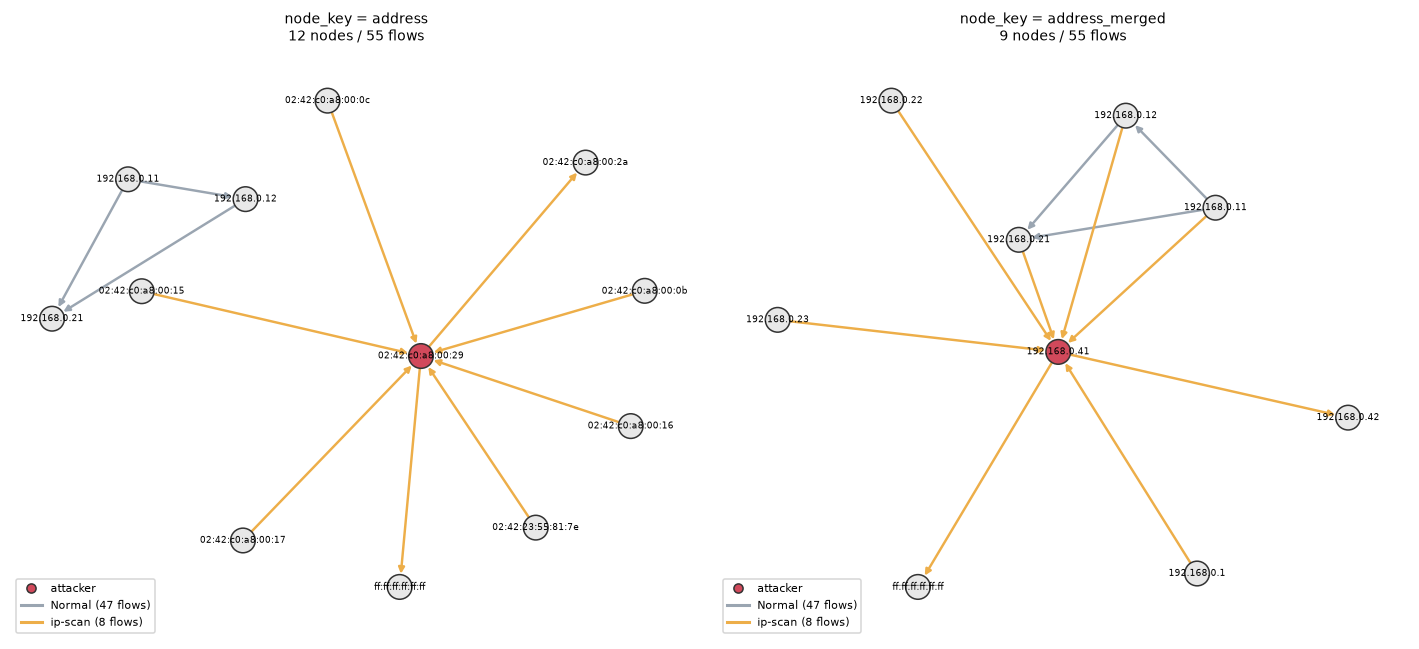

In [5]:
COLORS = {"Normal": "#9aa5b1", "ddos": "#d1495b", "ip-scan": "#edae49", "mitm": "#00798c",
          "port-scan": "#66a182", "replay": "#8d6cab"}

def find_window(graphs, cls):
    c = CLASSES.index(cls)
    return max((g for g in graphs if (g.flow_y == c).any()), key=lambda g: (g.flow_y == c).sum().item())

def draw(ax, data, g, key, title):
    # 由 flow_id 取回位址名稱 (只用於畫圖標籤)
    fids = g.flow_id.numpy()
    s_addr = data["df"].loc[fids, "sAddress"].to_numpy()
    d_addr = data["df"].loc[fids, "rAddress"].to_numpy()
    if key == "address_merged":
        s_addr = np.array([m2i.get(a, a) for a in s_addr]); d_addr = np.array([m2i.get(a, a) for a in d_addr])
    G = nx.MultiDiGraph()
    handles = [plt.Line2D([], [], marker='o', ls='', mfc='#d1495b', mec='#333', label='attacker')]
    for s, d, y in zip(s_addr, d_addr, g.flow_y.numpy()):
        G.add_edge(s, d, cls=CLASSES[y])
    pos = nx.spring_layout(nx.Graph(G), seed=1, k=1.2)
    attacker = {"192.168.0.41", "02:42:c0:a8:00:29"}
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=260,
                           node_color=["#d1495b" if n in attacker else "#e8e8e8" for n in G.nodes],
                           edgecolors="#333")
    for cls, col in COLORS.items():
        es = [(u, v) for u, v, a in G.edges(data=True) if a["cls"] == cls]
        if es:
            nx.draw_networkx_edges(G, pos, edgelist=list(set(es)), ax=ax, edge_color=col, width=1.6,
                                   arrows=True, arrowsize=8)
            handles.append(plt.Line2D([], [], color=col, lw=2, label=f"{cls} ({len(es)} flows)"))
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    ax.set_title(f"{title}\n{G.number_of_nodes()} nodes / {len(fids)} flows", fontsize=9)
    ax.legend(handles=handles, fontsize=7, loc="lower left"); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
g_a = find_window(graphs_by_key[("address", 10.0)], "ip-scan")
t0 = data["df"].loc[g_a.flow_id[0].item(), "start"]
g_m = next(g for g in graphs_by_key[("address_merged", 10.0)] if g.flow_id[0].item() == g_a.flow_id[0].item())
draw(axes[0], data, g_a, "address", "node_key = address")
draw(axes[1], data, g_m, "address_merged", "node_key = address_merged")
plt.tight_layout(); plt.show()

## 2. 模型：EdgeGAT

2 層 `GATConv` (hidden 64, 4 heads, `edge_dim`) → 對每筆 flow 取 `[h_src, h_dst, flow 特徵]` → MLP 分類。
loss 只計算 train flow；early stopping 依 val (detection F1 / identification macro-F1)。

消融用的兩個變體共用同一個類別：`n_layers=0` (無 message passing，只用節點聚合特徵)、`use_nodes=False` (只看 flow 特徵)。

In [6]:
g0 = graphs_by_key[("address_merged", 10.0)][0]
dims = dict(node_dim=g0.x.size(1), edge_dim=g0.edge_attr.size(1), flow_dim=g0.flow_x.size(1), n_classes=6)
print(dims)
variants = {
    "gnn_gat_w10_merged (2-layer GAT)": EdgeGAT(**dims),
    "gnn_ctx_w10_merged (0-layer, 無 message passing)": EdgeGAT(**dims, n_layers=0),
    "gnn_flowonly_mlp (只看 flow 特徵)": EdgeGAT(**dims, use_nodes=False),
}
print(variants["gnn_gat_w10_merged (2-layer GAT)"])
pd.Series({k: sum(p.numel() for p in m.parameters()) for k, m in variants.items()}, name="n_params").to_frame()

{'node_dim': 106, 'edge_dim': 53, 'flow_dim': 52, 'n_classes': 6}
EdgeGAT(
  (convs): ModuleList(
    (0): GATConv(106, 64, heads=4)
    (1): GATConv(256, 64, heads=4)
  )
  (classifier): Sequential(
    (0): Linear(in_features=564, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=6, bias=True)
  )
)


,n_params
gnn_gat_w10_merged (2-layer GAT),158406
"gnn_ctx_w10_merged (0-layer, 無 message passing)",17350
gnn_flowonly_mlp (只看 flow 特徵),125638


### 2.1 (選用) 重新訓練一次

`RUN_TRAINING = True` 時用 `scripts/train_gnn.py` 的 `train_one()` 以代表變體設定訓練 seed 0，只印 val / test 分數，不寫預測檔。

In [7]:
if RUN_TRAINING:
    sys.path.insert(0, str(ROOT / "scripts"))
    from train_gnn import train_one, predict
    args = Namespace(task="identification", hidden=64, heads=4, layers=2, flow_only=False, dropout=0.2,
                     lr=1e-3, weight_decay=1e-4, batch_size=32, epochs=100, patience=20,
                     class_weight="none", verbose=False)
    graphs = graphs_by_key[("address_merged", 10.0)]
    model, loader, best, n_ep = train_one(args, graphs, 6, seed=0)
    _, sp, y, proba = predict(model, loader)
    t = sp == SPLIT_CODE["test"]
    print(f"val macro-F1={best:.4f} (epochs={n_ep}) | test macro-F1="
          f"{identification_metrics(y[t], proba[t].argmax(1))['macro_f1']:.4f}")
else:
    print("RUN_TRAINING=False：略過訓練，以下使用 results/predictions/ 中已提交的 5-seed 預測。")

RUN_TRAINING=False：略過訓練，以下使用 results/predictions/ 中已提交的 5-seed 預測。


## 3. 結果 (test，5 seeds mean ± std)

代表變體依 **val** 選出 (`docs/EVALUATION_PROTOCOL.md` §4)：detection = `gnn_gat_w5`，identification = `gnn_gat_w10_merged`。
`val` 欄為 val split 上的 F1 / macro-F1，用來選變體；test 只在最後看一次。

In [8]:
def load_runs(method, task, seeds=range(5)):
    rows = []
    y_true = y_all if task == "identification" else load_split(task="detection", split_name=SPLIT)["y_all"]
    for seed in seeds:
        d = PRED_DIR / method / SPLIT
        p = pd.read_csv(d / f"{task}_seed{seed}.csv")
        v = pd.read_csv(d / f"{task}_seed{seed}_val.csv")
        yt, yv = y_true.loc[p["flow_id"]].to_numpy(), y_true.loc[v["flow_id"]].to_numpy()
        if task == "detection":
            m = detection_metrics(yt, p["y_pred"].to_numpy(), p["score"].to_numpy())
            m["val"] = detection_metrics(yv, v["y_pred"].to_numpy())["f1"]
        else:
            m = identification_metrics(yt, p["y_pred"].to_numpy())
            m["val"] = identification_metrics(yv, v["y_pred"].to_numpy())["macro_f1"]
        rows.append({"method": method, "seed": seed, **m})
    return pd.DataFrame(rows)

def summary(methods, task, cols):
    r = pd.concat([load_runs(m, task) for m in methods])
    g = r.groupby("method", sort=False)[cols]
    mean, std = g.mean(), g.std()
    return mean.round(4).astype(str) + " ± " + std.round(4).astype(str), mean

y_det = load_split(task="detection", split_name=SPLIT)["y_all"]

In [9]:
DET = ["rf_baseline", "dt_baseline", "ann_baseline", "gnn_gat_w5", "gnn_gat_w10"]
det_tab, det_mean = summary(DET, "detection", ["f1", "pr_auc", "fpr", "recall", "precision", "val"])
det_tab

,f1,pr_auc,fpr,recall,precision,val
method,,,,,,
rf_baseline,0.9803 ± 0.0006,0.9938 ± 0.0008,0.0082 ± 0.0003,0.9944 ± 0.0004,0.9667 ± 0.0011,0.9885 ± 0.0003
dt_baseline,0.9805 ± 0.0008,0.9687 ± 0.0015,0.007 ± 0.0004,0.9898 ± 0.0005,0.9714 ± 0.0016,0.9854 ± 0.0012
ann_baseline,0.9779 ± 0.0014,0.9906 ± 0.0026,0.0061 ± 0.0004,0.9812 ± 0.0026,0.9747 ± 0.0015,0.9852 ± 0.0018
gnn_gat_w5,0.9703 ± 0.0022,0.9936 ± 0.0008,0.0112 ± 0.0015,0.9865 ± 0.0022,0.9547 ± 0.0057,0.9865 ± 0.0007
gnn_gat_w10,0.9636 ± 0.0018,0.9922 ± 0.0014,0.0117 ± 0.0025,0.975 ± 0.0099,0.9526 ± 0.0091,0.9798 ± 0.0017


In [10]:
IDN = ["rf_baseline", "dt_baseline", "ann_baseline", "gnn_gat_w10", "gnn_gat_w10_merged"]
F1_COLS = [f"f1_{c}" for c in CLASSES]
idn_tab, idn_mean = summary(IDN, "identification", ["macro_f1", *F1_COLS, "val"])
idn_tab

,macro_f1,f1_Normal,f1_ddos,f1_ip-scan,f1_mitm,f1_port-scan,f1_replay,val
method,,,,,,,,
rf_baseline,0.8801 ± 0.0003,0.9952 ± 0.0001,0.9983 ± 0.0006,0.5308 ± 0.0,0.903 ± 0.0015,0.9301 ± 0.0009,0.9231 ± 0.0015,0.8865 ± 0.0008
dt_baseline,0.8753 ± 0.0003,0.9946 ± 0.0001,0.9962 ± 0.0006,0.5308 ± 0.0,0.8876 ± 0.001,0.9326 ± 0.0011,0.9102 ± 0.0009,0.8823 ± 0.0005
ann_baseline,0.8693 ± 0.0019,0.9955 ± 0.0002,0.9485 ± 0.0061,0.5288 ± 0.0011,0.9225 ± 0.0011,0.9209 ± 0.0018,0.8999 ± 0.006,0.8837 ± 0.0007
gnn_gat_w10,0.9242 ± 0.0161,0.9912 ± 0.002,0.9082 ± 0.0545,0.9351 ± 0.0443,0.9207 ± 0.0045,0.9905 ± 0.0053,0.7997 ± 0.027,0.9337 ± 0.0046
gnn_gat_w10_merged,0.9496 ± 0.0069,0.9942 ± 0.0006,0.9054 ± 0.0352,0.9529 ± 0.0239,0.9728 ± 0.0069,0.9996 ± 0.0006,0.8731 ± 0.0157,0.9597 ± 0.0008


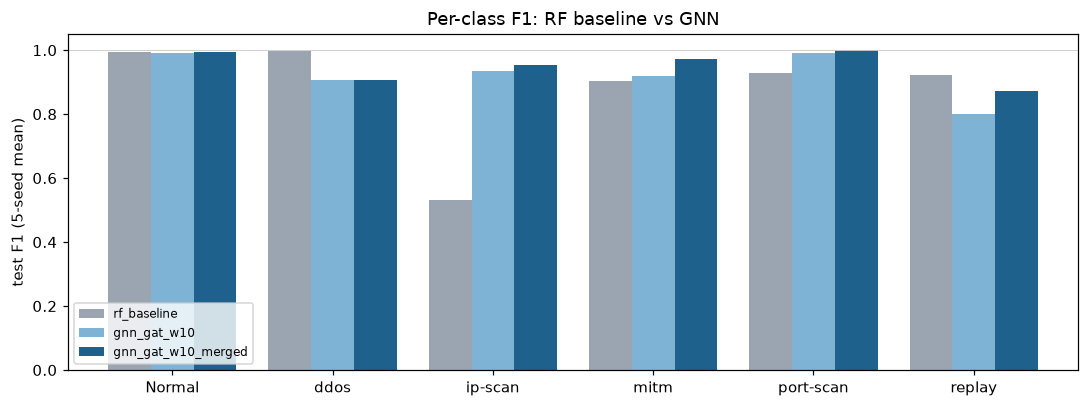

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
plot = idn_mean.loc[["rf_baseline", "gnn_gat_w10", "gnn_gat_w10_merged"], F1_COLS]
plot.columns = CLASSES
plot.T.plot.bar(ax=ax, width=0.8, color=["#9aa5b1", "#7fb3d5", "#1f618d"])
ax.set_ylabel("test F1 (5-seed mean)"); ax.set_ylim(0, 1.05); ax.set_title("Per-class F1: RF baseline vs GNN")
ax.axhline(1, color="#ccc", lw=0.6); plt.xticks(rotation=0); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**觀察**
- **Detection**：GNN (`gnn_gat_w5`) F1 略低於 RF 基線，PR-AUC 相同。圖結構對「是否為攻擊」幫助有限。
- **Identification**：主要價值在攻擊類型辨識，macro-F1 從 0.880 提升到 0.950；最大改善是 **ip-scan (0.531 → 0.953)**。
- **節點合併** 是調參中唯一明顯有效的改動 (mitm / replay 改善)；class weight、層數、hidden size 的差異都在雜訊範圍內 (見 `docs/GNN_RESULTS.md` 調參表)。

## 4. Confusion matrix (5 seeds 加總，列正規化)

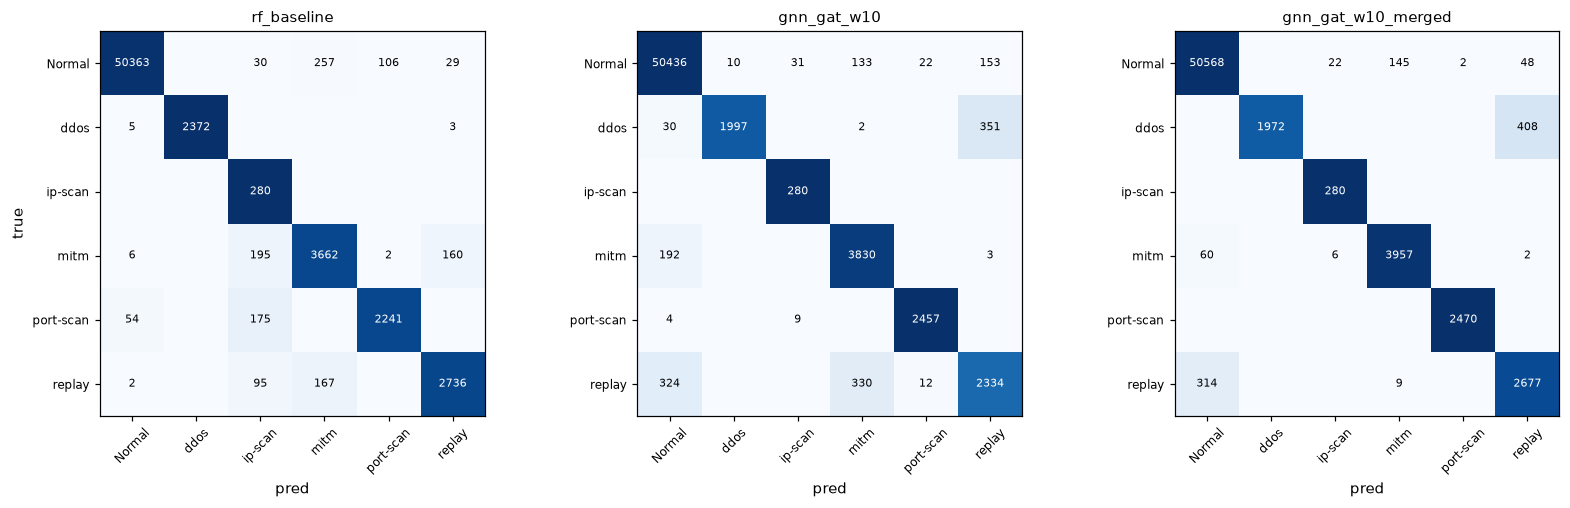

In [12]:
def confusion(method, task="identification"):
    n = len(CLASSES)
    cm = np.zeros((n, n), dtype=int)
    for seed in range(5):
        p = pd.read_csv(PRED_DIR / method / SPLIT / f"{task}_seed{seed}.csv")
        np.add.at(cm, (y_all.loc[p["flow_id"]].to_numpy(), p["y_pred"].to_numpy()), 1)
    return pd.DataFrame(cm, index=CLASSES, columns=CLASSES)

CM_METHODS = ["rf_baseline", "gnn_gat_w10", "gnn_gat_w10_merged"]
cms = {m: confusion(m) for m in CM_METHODS}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, m in zip(axes, CM_METHODS):
    cm = cms[m]; norm = cm.div(cm.sum(axis=1), axis=0)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm.iat[i, j]:
                ax.text(j, i, f"{cm.iat[i, j]}", ha="center", va="center", fontsize=7,
                        color="white" if norm.iat[i, j] > 0.5 else "black")
    ax.set_xticks(range(6), CLASSES, rotation=45, fontsize=8); ax.set_yticks(range(6), CLASSES, fontsize=8)
    ax.set_xlabel("pred"); ax.set_title(m, fontsize=10)
axes[0].set_ylabel("true"); plt.tight_layout(); plt.show()

In [13]:
pairs = [("Normal", "ip-scan"), ("port-scan", "ip-scan"), ("mitm", "ip-scan"), ("replay", "ip-scan"),
         ("replay", "mitm"), ("ddos", "replay"), ("replay", "Normal")]
pd.DataFrame({m: [cms[m].loc[t, p] for t, p in pairs] for m in CM_METHODS},
             index=[f"{t} → {p}" for t, p in pairs])

,rf_baseline,gnn_gat_w10,gnn_gat_w10_merged
Normal → ip-scan,30,31,22
port-scan → ip-scan,175,9,0
mitm → ip-scan,195,0,6
replay → ip-scan,95,0,0
replay → mitm,167,330,9
ddos → replay,3,351,408
replay → Normal,2,324,314


- **ip-scan 誤報**：RF 會把其他攻擊中的 ARP flow 誤判為 ip-scan；GNN 靠同一窗口內攻擊者節點的其他行為 (掃描 / TCP 連線) 分辨。
- **replay → mitm**：未合併時攻擊者的 ARP (MAC 節點) 與 TCP (IP 節點) 行為被拆開，合併後大幅下降。

### 4.1 剩餘錯誤集中在單一攻擊事件

以 `block_id` (攻擊事件) 分組。**僅作分析，未用於選模型。**

In [14]:
block = pd.read_csv(ROOT / "data" / "splits" / f"{SPLIT}.csv", index_col="flow_id")["block_id"]
rows = []
for seed in range(5):
    p = pd.read_csv(PRED_DIR / "gnn_gat_w10_merged" / SPLIT / f"identification_seed{seed}.csv", index_col="flow_id")
    t = pd.DataFrame({"true": y_all.loc[p.index].map(dict(enumerate(CLASSES))),
                      "pred": p["y_pred"].map(dict(enumerate(CLASSES))), "block": block.loc[p.index]})
    rows.append(t[t["true"] != t["pred"]])
err = pd.concat(rows)
(err.groupby(["true", "pred", "block"]).size().rename("errors (5 seeds)")
    .sort_values(ascending=False).head(10).to_frame())

errors (5 seeds)
true   pred   block                  
ddos   replay E39                 408
replay Normal E37                 167
              E21                 147
Normal mitm   E61                  54
              E67                  50
       replay E21                  26
mitm   Normal E40                  19
              E49                  16
Normal mitm   E18                  16
              E39                  15

- ddos → replay 幾乎全部來自事件 `E39`，另一個 test ddos 事件完全正確，屬於事件層級的泛化問題。
- replay → Normal 主要來自 `E21` / `E37`。
- test 中 ddos / replay 各只有 2 個事件，單一事件的錯誤會大幅影響類別 F1，報告中需說明。

## 5. 消融：提升來自哪裡？

問題：GNN 的提升來自 GAT 的 **message passing**，還是只來自「同一時間窗口內其他 flow」的 **上下文**？

### 5.1 GNN 內部消融 (identification，window 10，address_merged，epochs 400 / patience 30)

In [15]:
ABL = ["gnn_flowonly_mlp", "gnn_ctx_w10_merged", "gnn_gat_w10_merged"]
abl_tab, abl_mean = summary(ABL, "identification", ["macro_f1", "f1_ip-scan", "f1_mitm", "f1_replay", "val"])
abl_tab.insert(0, "說明", ["只看 flow 特徵", "0 層 GAT：flow + 節點聚合特徵", "完整 2 層 GAT (代表變體)"])
abl_tab

,說明,macro_f1,f1_ip-scan,f1_mitm,f1_replay,val
method,,,,,,
gnn_flowonly_mlp,只看 flow 特徵,0.7785 ± 0.0477,0.2739 ± 0.25,0.8861 ± 0.0035,0.7381 ± 0.0102,0.7974 ± 0.0461
gnn_ctx_w10_merged,0 層 GAT：flow + 節點聚合特徵,0.9636 ± 0.0113,0.9334 ± 0.0425,0.9593 ± 0.0068,0.9413 ± 0.0063,0.959 ± 0.0011
gnn_gat_w10_merged,完整 2 層 GAT (代表變體),0.9496 ± 0.0069,0.9529 ± 0.0239,0.9728 ± 0.0069,0.8731 ± 0.0157,0.9597 ± 0.0008


**message passing 幾乎沒有貢獻**：拿掉 GAT 層後 val 相同、test 甚至略高；提升來自節點聚合特徵 (= 同一窗口內同一主機的其他 flow)。

### 5.2 不用 GNN：RF + 上下文特徵 (`scripts/ablation_rf_context.py`)

| context | 聚合範圍 | 時間範圍 |
|---|---|---|
| `node` (`rf_ctx_*`) | 同主機 | 固定窗口 (含窗口內未來) |
| `global` (`rf_gctx_*`) | 全網路 | 固定窗口 |
| `causal_node` (`rf_cctx_*`) | 同主機 | 只看過去 W 秒 |
| `causal_global` (`rf_cgctx_*`) | 全網路 | 只看過去 W 秒 |

In [16]:
RF_DET = ["rf_baseline", "rf_ctx_w10", "rf_gctx_w5", "rf_cctx_w5_merged", "rf_cgctx_w10", "gnn_gat_w5"]
RF_IDN = ["rf_baseline", "rf_ctx_w10_merged", "rf_gctx_w5", "rf_cctx_w10_merged", "rf_cgctx_w10", "gnn_gat_w10_merged"]
_, d = summary(RF_DET, "detection", ["f1", "fpr", "val"])
_, i = summary(RF_IDN, "identification", ["macro_f1", "f1_ip-scan", "val"])
ctx = ["(none)", "node", "global", "causal_node", "causal_global", "GNN"]
pd.concat([d.reset_index().add_prefix("det_"), i.reset_index().add_prefix("idn_")], axis=1) \
  .set_index(pd.Index(ctx, name="context")).round(4)

,det_method,det_f1,det_fpr,det_val,idn_method,idn_macro_f1,idn_f1_ip-scan,idn_val
context,,,,,,,,
(none),rf_baseline,0.9803,0.0082,0.9885,rf_baseline,0.8801,0.5308,0.8865
node,rf_ctx_w10,0.9912,0.0037,0.9983,rf_ctx_w10_merged,0.9904,0.9843,0.9689
global,rf_gctx_w5,0.9885,0.0014,0.9973,rf_gctx_w5,0.9043,0.5358,0.9562
causal_node,rf_cctx_w5_merged,0.9943,0.0024,0.9992,rf_cctx_w10_merged,0.9345,0.6692,0.9338
causal_global,rf_cgctx_w10,0.9895,0.0017,0.9950,rf_cgctx_w10,0.9008,0.5013,0.9300
GNN,gnn_gat_w5,0.9703,0.0112,0.9865,gnn_gat_w10_merged,0.9496,0.9529,0.9597


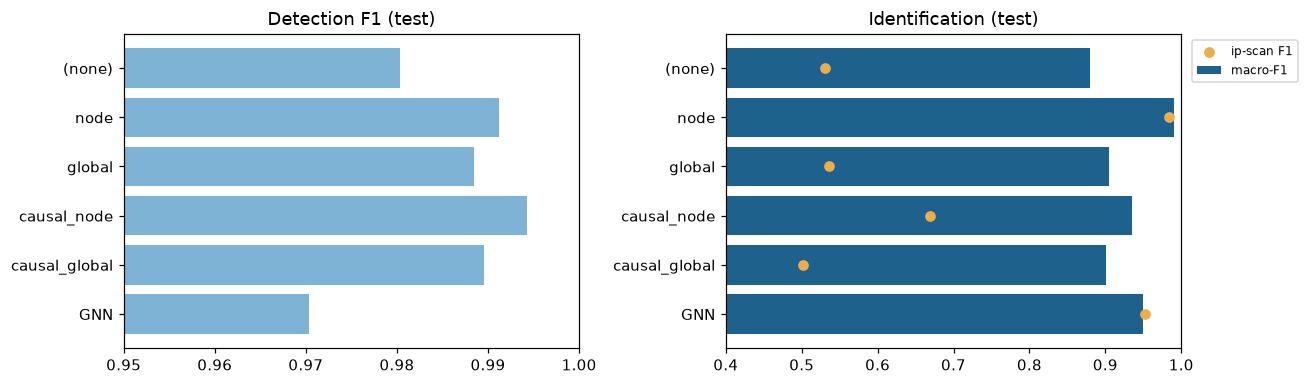

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].barh(ctx[::-1], d["f1"].to_numpy()[::-1], color="#7fb3d5"); axes[0].set_xlim(0.95, 1.0)
axes[0].set_title("Detection F1 (test)")
axes[1].barh(ctx[::-1], i["macro_f1"].to_numpy()[::-1], color="#1f618d", label="macro-F1")
axes[1].scatter(i["f1_ip-scan"].to_numpy()[::-1], ctx[::-1], color="#edae49", zorder=3, label="ip-scan F1")
axes[1].set_xlim(0.4, 1.0); axes[1].set_title("Identification (test)"); axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

### 5.3 攻擊者節點捷徑檢查

攻擊者固定是 `192.168.0.41 / 02:42:c0:a8:00:29`，整個資料集只有極少數 Normal flow 涉及它，
因此「認出攻擊者主機」幾乎等於「認出攻擊」。位址雖不是特徵，但同主機聚合特徵可能間接描繪出攻擊者主機。
下表依 flow 是否涉及攻擊者位址分群，計算 per-class recall (5 seeds 平均)，邏輯同 `scripts/analyze_attacker_node.py`。

In [18]:
ATTACKER = {"192.168.0.41", "02:42:c0:a8:00:29"}
involves = df["sAddress"].isin(ATTACKER) | df["rAddress"].isin(ATTACKER)
print("Normal flows 涉及攻擊者:", int((involves & (y_all == 0)).sum()))

AN = ["rf_baseline", "gnn_gat_w10_merged", "rf_ctx_w10_merged", "rf_gctx_w5", "rf_cctx_w10_merged", "rf_cgctx_w10"]
rows = []
for m in AN:
    for seed in range(5):
        p = pd.read_csv(PRED_DIR / m / SPLIT / f"identification_seed{seed}.csv", index_col="flow_id")
        t = pd.DataFrame({"y": y_all.loc[p.index], "pred": p["y_pred"], "inv": involves.loc[p.index]})
        for (inv, c), g in t.groupby(["inv", "y"]):
            rows.append({"method": m, "attacker_node": "yes" if inv else "no", "class": CLASSES[c],
                         "n": len(g), "recall": (g["pred"] == g["y"]).mean()})
r = pd.DataFrame(rows).groupby(["attacker_node", "class", "method"], sort=False).mean(numeric_only=True)
out = r["recall"].unstack("method")[AN].round(3)
out.insert(0, "n", r["n"].groupby(level=[0, 1], sort=False).first().astype(int))
out

Normal flows 涉及攻擊者: 9


method                       n  rf_baseline  gnn_gat_w10_merged  rf_ctx_w10_merged  rf_gctx_w5  rf_cctx_w10_merged  rf_cgctx_w10
attacker_node class                                                                                                             
no            Normal     10156        0.992               0.996              0.998       0.999               0.999         0.999
              mitm         642        0.997               0.981              0.994       0.995               0.999         0.997
              replay       160        0.999               0.633              0.981       0.984               0.992         0.994
yes           Normal         1        0.000               0.000              0.200       1.000               0.000         1.000
              mitm         163        0.568               0.990              1.000       0.951               0.788         0.880
              replay       440        0.880               0.987              0.945       0.924               0.943         0.887
              ddos         476        0.997               0.829              1.000       0.992               1.000         0.998
              ip-scan       56        1.000               1.000              1.000       0.432               0.936         0.536
              port-scan    494        0.907               1.000              0.997       0.960               1.000         0.993

## 6. 結論 (報告用)

1. **GNN 對 identification 有明顯提升** (macro-F1 0.880 → 0.950，ip-scan 0.531 → 0.953)；detection 則略低於 RF 基線。
2. **提升來自窗口上下文，不是 GAT 結構**：0 層 GAT 的 `gnn_ctx_w10_merged` 與完整 GAT 相當；同樣的上下文交給 RF (`rf_ctx_w10_merged`) 效果更好、訓練更快。
3. **Detection 的提升不依賴主機身分**：不分主機的 `global` / `causal_global` 上下文也能讓 RF 的 F1 提高、FPR 下降，且 causal 版本符合即時部署條件。
4. **ip-scan 的改善需要「同主機 + 窗口內未來」的上下文**；因為 ICS-Flow 只有單一攻擊者且攻擊者幾乎不產生正常流量，
   **這部分提升無法排除「間接辨認攻擊者主機」的可能**，需在報告中列為限制。
5. 非因果窗口在即時偵測時代表最多 W 秒的延遲；與嚴格因果的 LSTM 比較時需註明。
6. 剩餘錯誤集中在少數攻擊事件 (E39、E21、E37)；test 中 ddos / replay 各只有 2 個事件，類別 F1 的變異需一併說明。

**待討論**：`rf_ctx_w10_merged` 的 val 分數高於 GNN 代表變體，是否改列為「GNN 方法的簡化版」或獨立方法，需組內決定 (目前代表變體未更動)。